# Settings

In [186]:
using_simulation_data = False

#angles to study
examine_all_angles = False
angles_to_study = [-15, 0, 15]

bf_data_path = "./data_nsi/csv/beamformed_apodizations/003_real_data_angledelayfixed_angle31_rectangle.npy"

# Imports

In [187]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [188]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [189]:
def calculate_variables_simulation(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [190]:
def calculate_variables_real_data(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    samples = params["wave"]["samples"]
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [191]:
parameters = load_parameters("./parameters_real_data.json")
if using_simulation_data:
    params, pos, time = calculate_variables_simulation(parameters)
else:
    params, pos, time = calculate_variables_real_data(parameters)

Aperture:  0.8
Samples:  834
Upsampled samples:  3333
Step size:  1.6e-08 s
Maximal acquisition depth: 0.010008000000000001 m
Lateral step:  2.25e-05 m


# Load BF data

In [192]:
bf_matrices = np.load(bf_data_path)
tmp_matrix = np.zeros((bf_matrices.shape[0], bf_matrices.shape[1], len(angles_to_study)))

for i in range(len(angles_to_study)):
    tmp_matrix[:, :, i] = bf_matrices[:, :, np.where(np.array(params["wave"]["angles"]) == angles_to_study[i])[0][0]]

In [193]:
if not examine_all_angles:
    bf_matrices = tmp_matrix

# Display angles

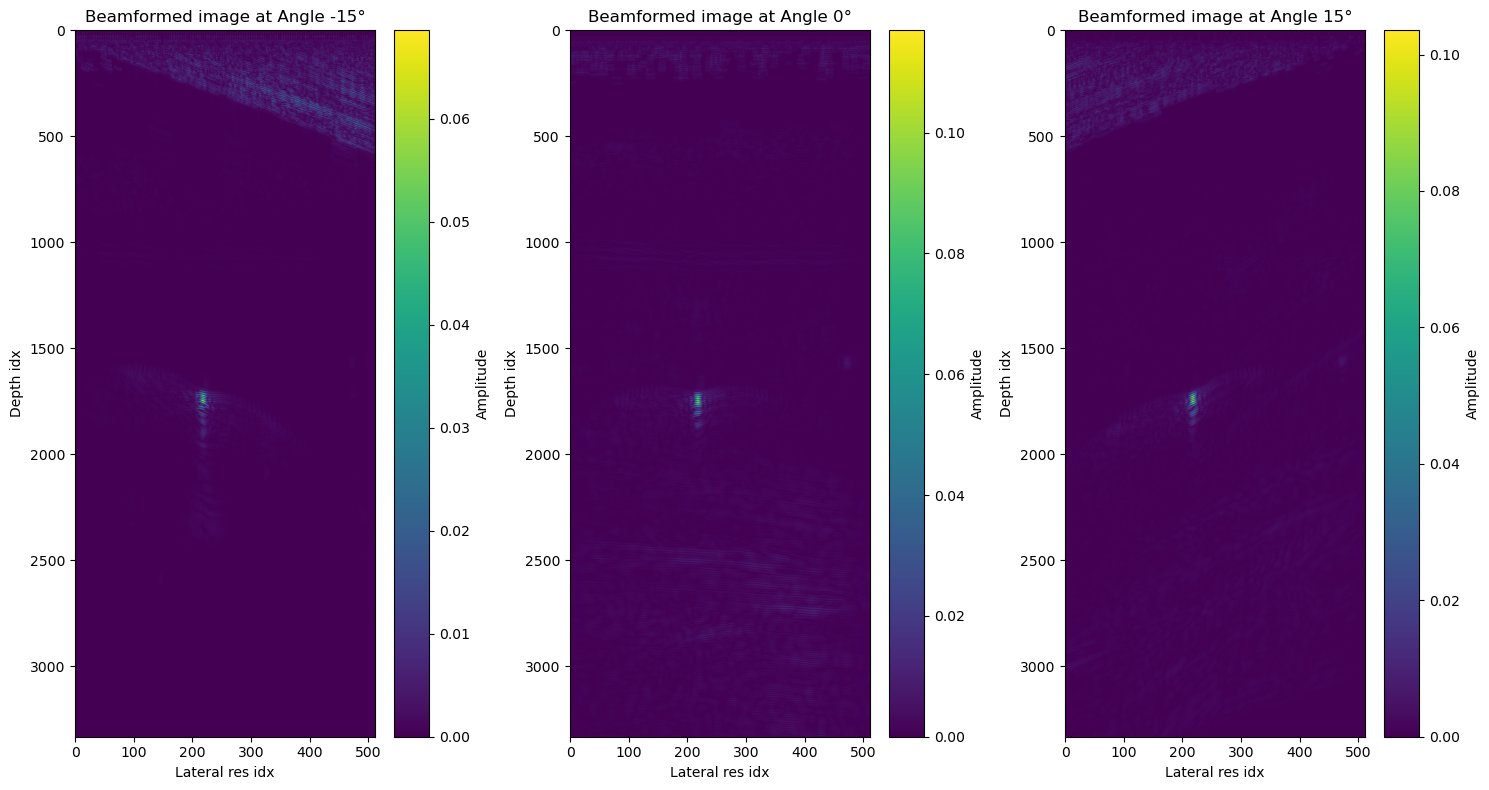

In [194]:

num_angles = bf_matrices.shape[2]
fig, axes = plt.subplots(nrows=1, ncols=num_angles, figsize=(15,8))

if num_angles == 1:
    axes = [axes]

for i in range(num_angles):
    im = axes[i].imshow(np.abs(bf_matrices[:,:,i]), aspect='auto', cmap='viridis')
    axes[i].set_title(f'Beamformed image at Angle {params["wave"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[i].set_xlabel('Lateral res idx')
    axes[i].set_ylabel('Depth idx')
    fig.colorbar(im, ax=axes[i], label='Amplitude')

plt.tight_layout()
plt.show()

# Get most energy axial profile

In [195]:
def extract_highest_value_region_all_angles(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices

## Images

Max value at angle -15°: 0.06857328163525851
Max value row: 50, col: 15


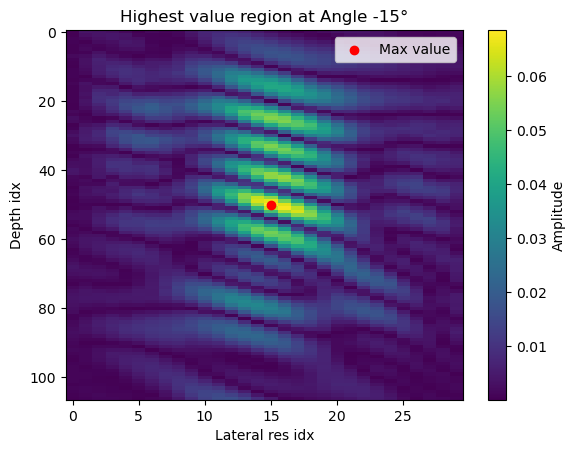

Max value at angle 0°: 0.11691645782107704
Max value row: 57, col: 15


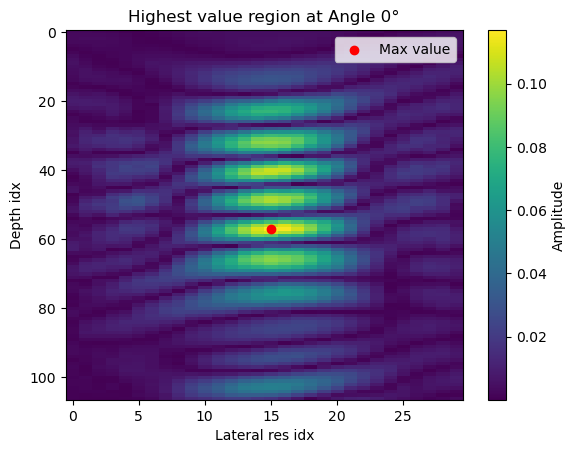

Max value at angle 15°: 0.10355028644090802
Max value row: 55, col: 15


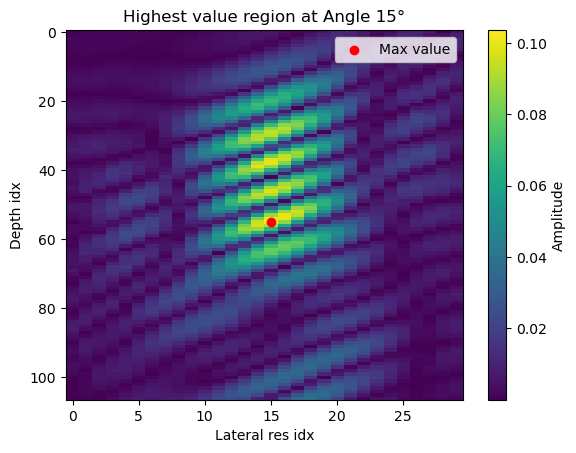

In [196]:
submatrix = extract_highest_value_region_all_angles(np.abs(bf_matrices), depth_margin= 50, lateral_margin= 15)

for i in range(num_angles):
        
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    print(f"Max value at angle {params["wave"]["angles"][i] if examine_all_angles else angles_to_study[i]}°: {submatrix[:,:,i][max_val_row, max_val_col]}")
    print(f"Max value row: {max_val_row}, col: {max_val_col}")
    plt.imshow(submatrix[:,:,i], aspect='auto', cmap='viridis')
    plt.title(f'Highest value region at Angle {params["wave"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    plt.xlabel('Lateral res idx')
    plt.ylabel('Depth idx')
    plt.colorbar(label='Amplitude')
    plt.scatter(max_val_col, max_val_row, color='red', label='Max value')
    plt.legend()
    plt.show()

## Curves

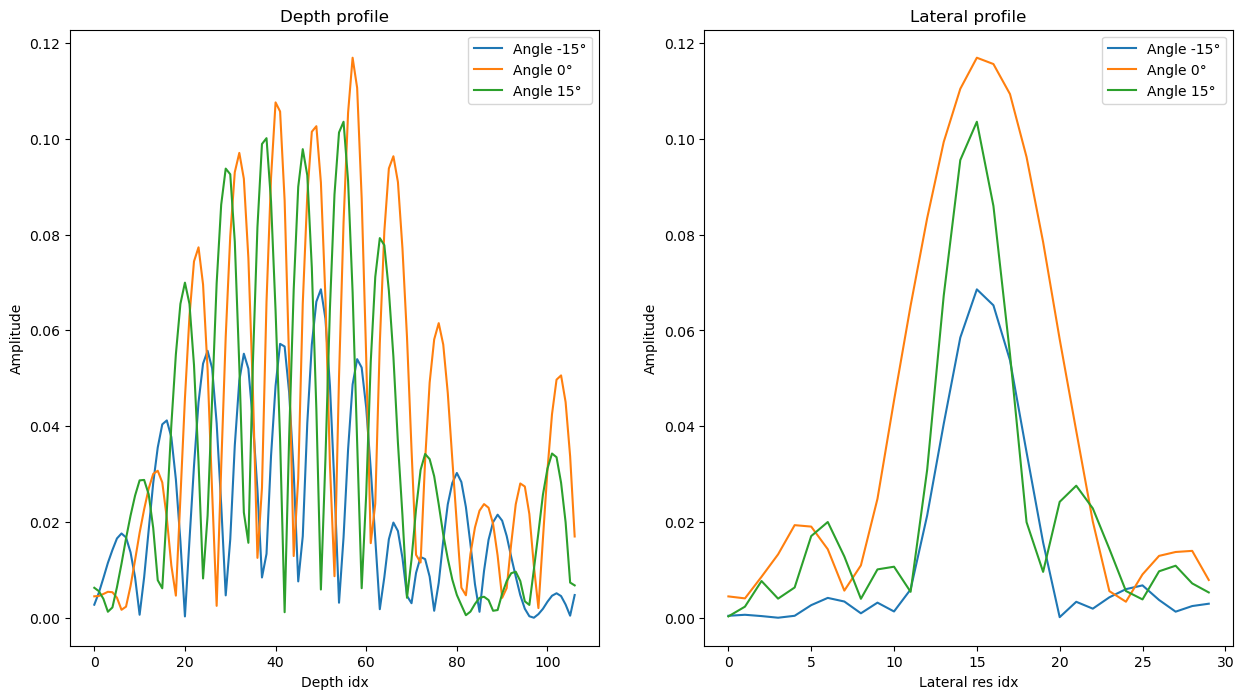

In [197]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,8))

for i in range(submatrix.shape[2]):
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    axes[0].plot(submatrix[:,:,i][:,max_val_col], label=f'Angle {params["wave"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[0].set_title('Depth profile')
    axes[0].set_xlabel('Depth idx')
    axes[0].set_ylabel('Amplitude')
    axes[0].legend()

    axes[1].plot(submatrix[:,:,i][max_val_row,:], label=f'Angle {params["wave"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[1].set_title('Lateral profile')
    axes[1].set_xlabel('Lateral res idx')
    axes[1].set_ylabel('Amplitude')
    axes[1].legend()